# Machine Learning

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/customer_rfm.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (5878, 9)


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,12,77556.46,2,5,5,255,At Risk
1,12347,2,8,4921.53,5,4,5,545,Champions
2,12348,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,Potential Loyalists
4,12350,310,1,334.40,2,1,2,212,Hibernating


In [4]:
#Select ML features
X = df[["Recency", "Frequency", "Monetary"]].copy()

print("ML Features Shape:", X.shape)
display(X.describe())

ML Features Shape: (5878, 3)


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


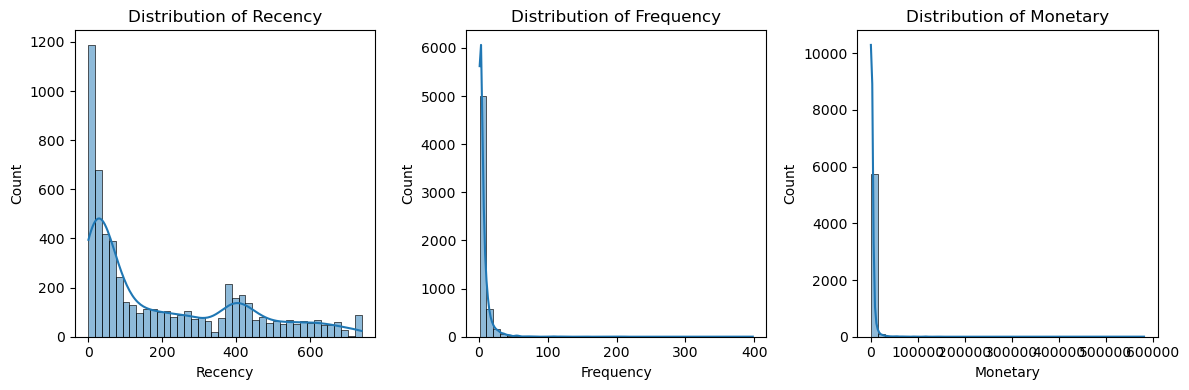

In [5]:
#Check the feature distributions
plt.figure(figsize=(12, 4))

for i, col in enumerate(X.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(X[col], bins=40, kde=True)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

Log transformation: Reduces the impact of extreme values and makes skewed distributions less pronounced.

StandardScaler: Puts all three features on a comparable scale.

In [6]:
X_log = np.log1p(X)

print("Distributions after Log Transformation:")
display(X_log.describe())

Distributions after Log Transformation:


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,4.454132,1.549588,6.816979
std,1.559404,0.809447,1.385486
min,0.693147,0.693147,1.373716
25%,3.295837,0.693147,5.838546
50%,4.574711,1.386294,6.767044
75%,5.942799,2.079442,7.718377
max,6.606650,5.988961,13.272485


In [8]:
import pandas as pd
import sklearn
from sklearn.preprocessing import StandardScaler

# Print the version to make sure it works
print("Scikit-learn version:", sklearn.__version__)

# Initialize the scaler
scaler = StandardScaler()

# Standardize the features (Make sure X_log is defined above this!)
X_scaled_array = scaler.fit_transform(X_log)

# Convert back to a clean Pandas DataFrame
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=["Recency", "Frequency", "Monetary"]
)

# Display the first few rows
display(X_scaled.head())


Scikit-learn version: 1.7.2


,Recency,Frequency,Monetary
0,0.856701,1.254496,3.206219
1,-2.151979,0.800166,1.215993
2,-0.079138,0.299207,0.573185
3,-0.935308,0.073946,1.139846
4,0.824527,-1.058146,-0.723024


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [10]:
#Calculate scores for different cluster counts
inertia_values = []
silhouette_values = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4355
K = 3, Silhouette Score = 0.3461
K = 4, Silhouette Score = 0.3647
K = 5, Silhouette Score = 0.3465
K = 6, Silhouette Score = 0.3367
K = 7, Silhouette Score = 0.3067
K = 8, Silhouette Score = 0.3006
K = 9, Silhouette Score = 0.2882
K = 10, Silhouette Score = 0.2852


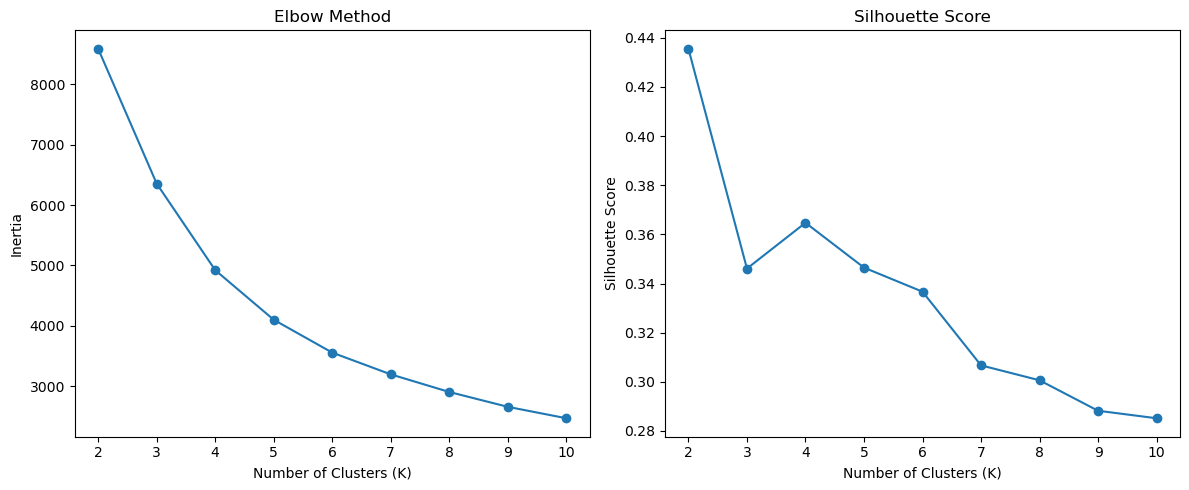

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(list(K), inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(list(K), silhouette_values, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rfm = pd.read_csv("../data/processed/customer_rfm.csv")

print("RFM Dataset Loaded!")
print("Shape:", rfm.shape)

display(rfm.head())

RFM Dataset Loaded!
Shape: (5878, 9)


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,12,77556.46,2,5,5,255,At Risk
1,12347,2,8,4921.53,5,4,5,545,Champions
2,12348,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,Potential Loyalists
4,12350,310,1,334.40,2,1,2,212,Hibernating


In [14]:
from sklearn.preprocessing import StandardScaler

X = rfm[["Recency", "Frequency", "Monetary"]].copy()

X_log = np.log1p(X)

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=["Recency", "Frequency", "Monetary"]
)

In [15]:
#Choose K = 4
# Train final K-Means model with 4 clusters

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["ML_Cluster"] = kmeans_final.fit_predict(X_scaled)

print("K-Means model trained successfully!")

display(rfm.head(10))

K-Means model trained successfully!


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,ML_Cluster
0,12346,326,12,77556.46,2,5,5,255,At Risk,2
1,12347,2,8,4921.53,5,4,5,545,Champions,2
2,12348,75,5,2019.40,3,4,4,344,Loyal Customers,3
3,12349,19,4,4428.69,5,3,5,535,Potential Loyalists,1
4,12350,310,1,334.40,2,1,2,212,Hibernating,0
5,12351,375,1,300.93,2,1,2,212,Hibernating,0
6,12352,36,10,2849.84,4,5,4,454,Champions,2
7,12353,204,2,406.76,2,2,2,222,Hibernating,0
8,12354,232,1,1079.40,2,1,3,213,Hibernating,0
9,12355,214,2,947.61,2,2,3,223,Hibernating,3


ML_Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


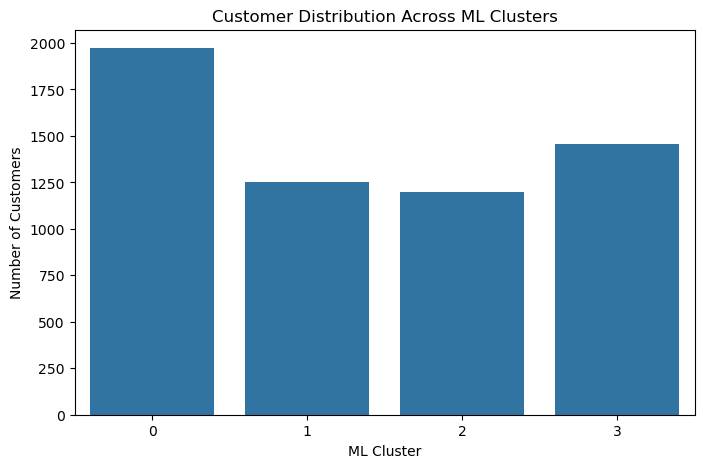

In [16]:
#Check the number of customers in each cluster
cluster_counts = rfm["ML_Cluster"].value_counts().sort_index()

print(cluster_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="ML_Cluster"
)

plt.title("Customer Distribution Across ML Clusters")
plt.xlabel("ML Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
cluster_profile = rfm.groupby("ML_Cluster").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(cluster_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
ML_Cluster,,,,,
0,1973,394.95,1.38,317.08,625601.80
1,1250,28.30,3.05,857.49,1071864.29
2,1196,27.71,19.28,10731.16,12834470.94
3,1459,230.07,5.06,1948.50,2842867.24


In [18]:
#Compare ML clustering with RFM segmentation
comparison = pd.crosstab(
    rfm["Segment"],
    rfm["ML_Cluster"]
)

display(comparison)

ML_Cluster,0,1,2,3
Segment,,,,
At Risk,186,0,14,625
Champions,0,138,1061,90
Hibernating,1432,0,0,94
Loyal Customers,4,173,116,415
New Customers,0,54,0,0
Others,335,210,0,220
Potential Loyalists,16,675,5,15


In [19]:
rfm.to_csv(
    "../data/processed/customer_rfm_ml.csv",
    index=False
)

cluster_profile.to_csv(
    "../data/processed/ml_cluster_profile.csv"
)

print("ML results saved successfully!")


ML results saved successfully!


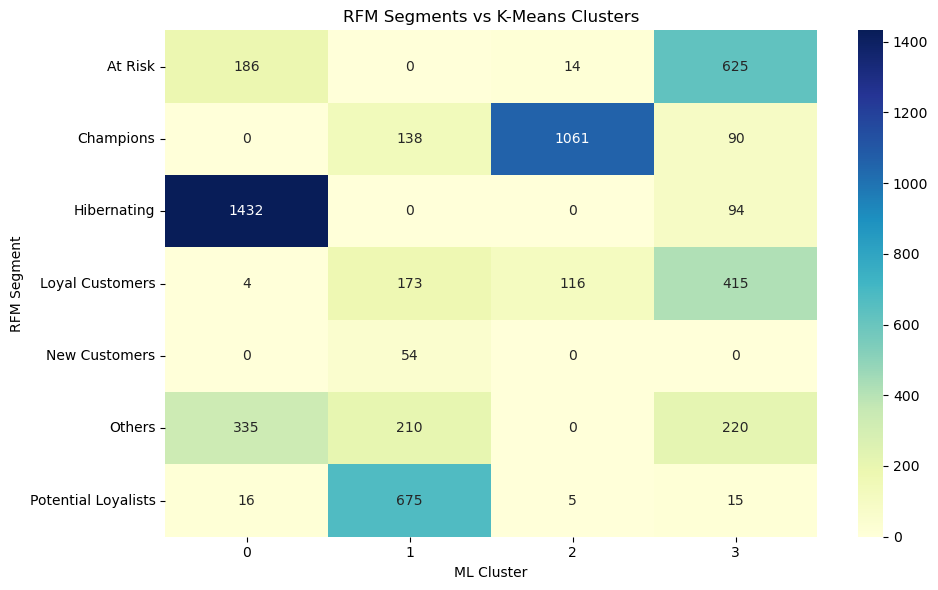

In [20]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("RFM Segments vs K-Means Clusters")
plt.xlabel("ML Cluster")
plt.ylabel("RFM Segment")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import silhouette_score

final_score = silhouette_score(
    X_scaled,
    rfm["ML_Cluster"],
    sample_size=2000,
    random_state=42
)

print("Final K-Means Silhouette Score:", round(final_score, 4))

print("\nCluster Distribution:")
print(rfm["ML_Cluster"].value_counts().sort_index())

Final K-Means Silhouette Score: 0.3647

Cluster Distribution:
ML_Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [22]:
comparison.to_csv(
    "../data/processed/rfm_ml_comparison.csv"
)

rfm.to_csv(
    "../data/processed/customer_rfm_ml.csv",
    index=False
)

cluster_profile.to_csv(
    "../data/processed/ml_cluster_profile.csv"
)

print("All ML outputs saved successfully!")

All ML outputs saved successfully!
